# Spring constant from a thermal tune, by the Sader method

This notebook reads a thermal tune, fits the resonance, and calculates the spring constant from the resonance frequency,
the quality factor and the cantilever's size. Run it from this folder, next to `thermal.nid` and `sader.py`.

In [1]:
from NSFopen.read import read
from sader import sader

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## The model

A thermal tune is an amplitude spectral density. Its power follows a simple harmonic oscillator plus white noise, and the
two add as powers, so the amplitude is the square root of their sum.

In [2]:
def sho(f, f0, Q, A0, noise):
    return np.sqrt(noise**2 + A0**2 * f0**4 / ((f**2 - f0**2) ** 2 + (f * f0 / Q) ** 2))

## Open the thermal tune

The length and width are the nominal values of the cantilever, in m. Measure them for a better result.

In [3]:
L = 225e-6
W = 40e-6

afm = read("thermal.nid", verbose=False)
amplitude = afm.data.Sweep.FFT["Amplitude Spectral Density"][0]
frequency = np.linspace(afm.param.X["min"][0], afm.param.X["min"][0] + afm.param.X["range"][0], len(amplitude))

keep = frequency > 1000  # leave out the low frequency part
frequency, amplitude = frequency[keep], amplitude[keep]

## Fit around the peak

The fit uses 15 kHz at each side of the highest point. Its starting values come from the data.

In [4]:
peak = frequency[np.argmax(amplitude)]
band = np.abs(frequency - peak) < 15e3
x, y = frequency[band], amplitude[band]

start = [peak, 300, y.max() / 300, np.median(y)]
(f0, Q, A0, noise), covariance = curve_fit(sho, x, y, p0=start)
f0_error, Q_error = np.sqrt(np.diag(covariance))[:2]

k = sader(L, W, f0, Q)
print(f"Resonance: {f0 / 1e3:.2f} +- {f0_error / 1e3:.2f} kHz")
print(f"Q factor: {Q:.0f} +- {Q_error:.0f}")
print(f"Spring constant (Sader): {k:.1f} N/m")

Resonance: 179.75 +- 0.00 kHz
Q factor: 417 +- 3
Spring constant (Sader): 24.0 N/m


The Nanosurf software fitted the same tune when it was recorded and stored its results in the file. Its spring constant
comes from the thermal method, which is a different calculation, so expect it to be close but not equal.

In [5]:
info = afm.param["HeaderDump"]["DataSet-Info"]
for name in ("Cantilever type", "Frequency:", "Q Factor:", "Spring Constant:"):
    print(f"{name:20s} {info[name]}")

Cantilever type      ACL-A
Frequency:           179.8kHz
Q Factor:            442
Spring Constant:     27.13 N/m


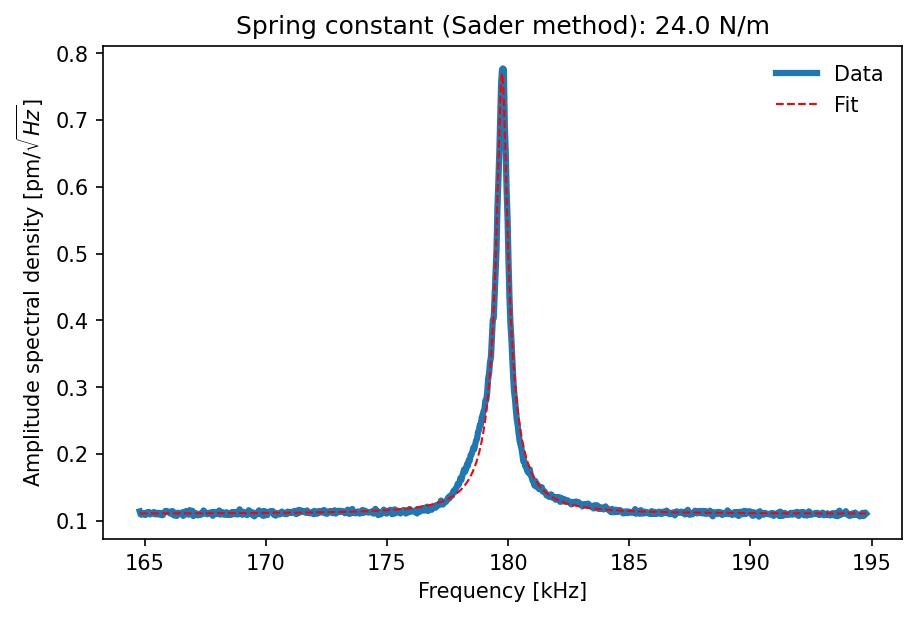

In [6]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained", dpi=150)
ax.plot(x / 1e3, y * 1e12, linewidth=3, label="Data")
ax.plot(x / 1e3, sho(x, f0, Q, A0, noise) * 1e12, linewidth=1, color="r", linestyle="--", label="Fit")
ax.set(xlabel="Frequency [kHz]", ylabel=r"Amplitude spectral density [pm/$\sqrt{Hz}$]",
       title=f"Spring constant (Sader method): {k:.1f} N/m")
ax.legend(frameon=False)
plt.show()